<a href="https://colab.research.google.com/github/Madjdadj/Deep-Learning-CNN/blob/main/Projet_CNN_Tomates.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub
import kagglehub
path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
print("Dataset téléchargé dans :", path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Dataset téléchargé dans : /kaggle/input/plantvillage-dataset


In [2]:
import os
for root, dirs, files in os.walk(path):
    if "Tomato___healthy" in dirs and os.path.basename(root) == "color":
        SRC = root
        break
print("Dossier source :", SRC)

Dossier source : /kaggle/input/plantvillage-dataset/plantvillage dataset/color


In [3]:
CLASSES = ["Tomato___healthy", "Tomato___Early_blight", "Tomato___Late_blight"]
for c in CLASSES:
    print(c, "->", len(os.listdir(os.path.join(SRC, c))), "images")

Tomato___healthy -> 1591 images
Tomato___Early_blight -> 1000 images
Tomato___Late_blight -> 1909 images


In [4]:
import random, shutil
from pathlib import Path

SEED = 42
random.seed(SEED)
DST = Path("/content/data")
if DST.exists():
    shutil.rmtree(DST)

for c in CLASSES:
    imgs = sorted(os.listdir(os.path.join(SRC, c)))
    random.shuffle(imgs)
    n = len(imgs)
    n_train, n_val = int(0.70 * n), int(0.15 * n)
    splits = {"train": imgs[:n_train],
              "val":   imgs[n_train:n_train + n_val],
              "test":  imgs[n_train + n_val:]}
    for split, files in splits.items():
        out = DST / split / c
        out.mkdir(parents=True, exist_ok=True)
        for f in files:
            shutil.copy(os.path.join(SRC, c, f), out / f)

for split in ["train", "val", "test"]:
    for c in CLASSES:
        print(split, c, len(os.listdir(DST / split / c)))

train Tomato___healthy 1113
train Tomato___Early_blight 700
train Tomato___Late_blight 1336
val Tomato___healthy 238
val Tomato___Early_blight 150
val Tomato___Late_blight 286
test Tomato___healthy 240
test Tomato___Early_blight 150
test Tomato___Late_blight 287


In [5]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

base_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder(DST / "train", transform=base_tf)
val_ds   = datasets.ImageFolder(DST / "val",   transform=base_tf)
test_ds  = datasets.ImageFolder(DST / "test",  transform=base_tf)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2)

print("Classes :", train_ds.class_to_idx)
print("Train / Val / Test :", len(train_ds), len(val_ds), len(test_ds))

images, labels = next(iter(train_loader))
print(images.shape)   # attendu : [32, 3, 224, 224]

Classes : {'Tomato___Early_blight': 0, 'Tomato___Late_blight': 1, 'Tomato___healthy': 2}
Train / Val / Test : 3149 674 677
torch.Size([32, 3, 224, 224])


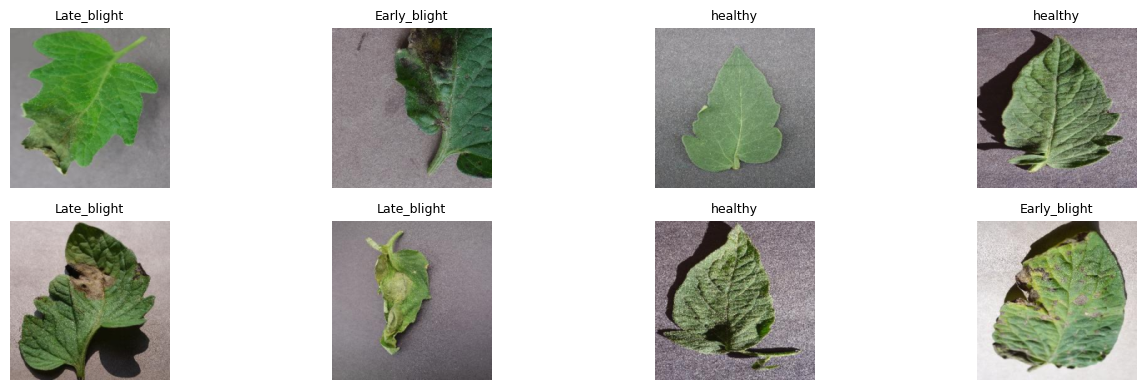

In [6]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(14, 4))
for i in range(8):
    img = images[i].permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
    plt.subplot(2, 4, i + 1)
    plt.imshow(np.clip(img, 0, 1))
    plt.title(train_ds.classes[labels[i]].replace("Tomato___", ""), fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
#madjda

In [7]:

import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet50_Weights

# 1. Choisir le GPU si disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

# 2. Charger ResNet-50 avec les poids ImageNet
weights = ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

# 3. Geler toutes les couches pré-entraînées
for param in model.parameters():
    param.requires_grad = False

# 4. Remplacer la couche finale par un classifieur à 3 classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(CLASSES))

# 5. Envoyer le modèle sur le GPU ou le CPU
model = model.to(device)

# Vérifier les paramètres entraînables
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Nombre de classes :", len(CLASSES))
print("Caractéristiques en entrée du classifieur :", num_features)
print("Paramètres totaux :", total_params)
print("Paramètres entraînables :", trainable_params)
print("Classes du dataset :", train_ds.class_to_idx)


Appareil utilisé : cuda
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 203MB/s]


Nombre de classes : 3
Caractéristiques en entrée du classifieur : 2048
Paramètres totaux : 23514179
Paramètres entraînables : 6147
Classes du dataset : {'Tomato___Early_blight': 0, 'Tomato___Late_blight': 1, 'Tomato___healthy': 2}


In [8]:

import torch.optim as optim

# Fonction de perte adaptée à la classification multiclasse
criterion = nn.CrossEntropyLoss()

# Optimiser uniquement la nouvelle couche fc
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

# Nombre d'époques
EPOCHS = 10

print("Fonction de perte :", criterion)
print("Optimiseur :", optimizer.__class__.__name__)
print("Learning rate :", 0.001)
print("Époques :", EPOCHS)


Fonction de perte : CrossEntropyLoss()
Optimiseur : Adam
Learning rate : 0.001
Époques : 10


In [9]:

import copy
import csv
import os

# Dossier de sauvegarde
RESULTS_DIR = "/content/feature_extraction_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

best_val_acc = 0.0
best_state = copy.deepcopy(model.state_dict())
history = []

for epoch in range(EPOCHS):
    # -------------------------
    # ENTRAINEMENT
    # -------------------------
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss_sum += loss.item() * batch_size
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # Enregistrer les métriques de cette époque
    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(
        f"Époque {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # Sauvegarder le meilleur modèle
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_state,
            os.path.join(RESULTS_DIR, "best_resnet50_feature_extraction.pth")
        )

# Restaurer le meilleur modèle
model.load_state_dict(best_state)

# Sauvegarder l'historique au format CSV
csv_path = os.path.join(RESULTS_DIR, "training_history.csv")

with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=history[0].keys())
    writer.writeheader()
    writer.writerows(history)

print("\nEntraînement terminé.")
print(f"Meilleure accuracy de validation : {best_val_acc:.4f}")
print("Historique sauvegardé :", csv_path)
print("Modèle sauvegardé :", os.path.join(
    RESULTS_DIR, "best_resnet50_feature_extraction.pth"
))


Époque 1/10 | Train Loss: 0.5110 | Train Acc: 0.8396 | Val Loss: 0.2968 | Val Acc: 0.8961
Époque 2/10 | Train Loss: 0.2544 | Train Acc: 0.9282 | Val Loss: 0.2022 | Val Acc: 0.9436
Époque 3/10 | Train Loss: 0.1876 | Train Acc: 0.9489 | Val Loss: 0.1669 | Val Acc: 0.9599
Époque 4/10 | Train Loss: 0.1693 | Train Acc: 0.9530 | Val Loss: 0.1440 | Val Acc: 0.9540
Époque 5/10 | Train Loss: 0.1340 | Train Acc: 0.9641 | Val Loss: 0.1300 | Val Acc: 0.9659
Époque 6/10 | Train Loss: 0.1216 | Train Acc: 0.9686 | Val Loss: 0.1178 | Val Acc: 0.9659
Époque 7/10 | Train Loss: 0.1088 | Train Acc: 0.9743 | Val Loss: 0.1116 | Val Acc: 0.9659
Époque 8/10 | Train Loss: 0.1074 | Train Acc: 0.9727 | Val Loss: 0.0961 | Val Acc: 0.9763
Époque 9/10 | Train Loss: 0.0978 | Train Acc: 0.9762 | Val Loss: 0.1011 | Val Acc: 0.9688
Époque 10/10 | Train Loss: 0.0838 | Train Acc: 0.9803 | Val Loss: 0.0950 | Val Acc: 0.9688

Entraînement terminé.
Meilleure accuracy de validation : 0.9763
Historique sauvegardé : /content/f

In [10]:

print("Fichiers des résultats :")
for filename in sorted(os.listdir(RESULTS_DIR)):
    filepath = os.path.join(RESULTS_DIR, filename)
    print(filename, "—", round(os.path.getsize(filepath) / 1024, 2), "Ko")


Fichiers des résultats :
best_resnet50_feature_extraction.pth — 92170.83 Ko
training_history.csv — 0.84 Ko


In [11]:
from google.colab import files
import os

for filename in [
    "best_resnet50_feature_extraction.pth",
    "training_history.csv"
]:
    filepath = os.path.join(RESULTS_DIR, filename)
    files.download(filepath)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

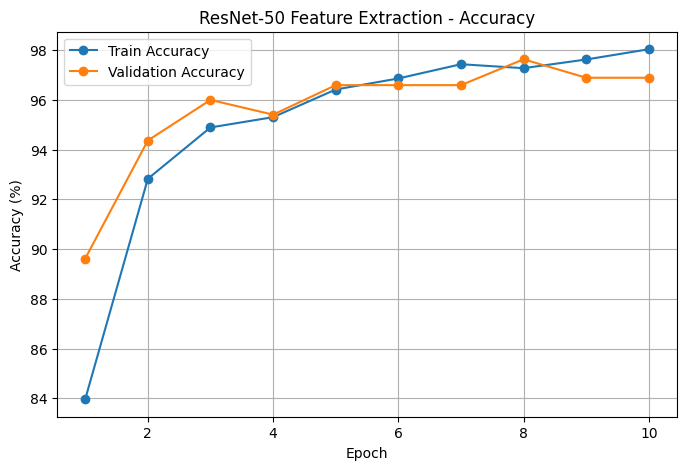

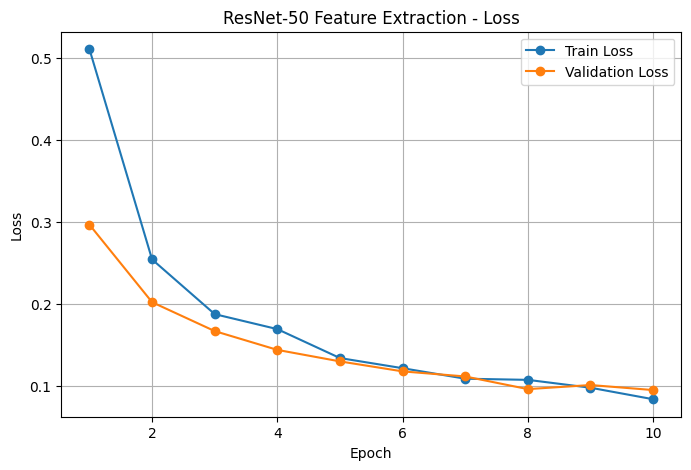

In [12]:
import matplotlib.pyplot as plt

epochs_fe = [h["epoch"] for h in history]

# Courbe d'accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs_fe, [h["train_accuracy"] * 100 for h in history], marker="o", label="Train Accuracy")
plt.plot(epochs_fe, [h["val_accuracy"] * 100 for h in history], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet-50 Feature Extraction - Accuracy")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(RESULTS_DIR, "accuracy_curve_fe.png"), dpi=150, bbox_inches="tight")
plt.show()

# Courbe de loss
plt.figure(figsize=(8, 5))
plt.plot(epochs_fe, [h["train_loss"] for h in history], marker="o", label="Train Loss")
plt.plot(epochs_fe, [h["val_loss"] for h in history], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet-50 Feature Extraction - Loss")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(RESULTS_DIR, "loss_curve_fe.png"), dpi=150, bbox_inches="tight")
plt.show()

In [13]:
import shutil
from google.colab import drive

drive.mount('/content/drive')
DEST = "/content/drive/MyDrive/projet-cnn/feature_extraction_results"
shutil.copytree(RESULTS_DIR, DEST, dirs_exist_ok=True)

print("Copié dans :", DEST)
for f in sorted(os.listdir(DEST)):
    print(" -", f)

Mounted at /content/drive
Copié dans : /content/drive/MyDrive/projet-cnn/feature_extraction_results
 - accuracy_curve_fe.png
 - best_resnet50_feature_extraction.pth
 - loss_curve_fe.png
 - training_history.csv


In [ ]:
#imene

In [14]:
!pip install -q albumentations

In [15]:
import os

print("Dataset existe :", os.path.exists("/content/data"))
print("Modèle précédent :", os.path.exists(
    "/content/feature_extraction_results/"
    "best_resnet50_feature_extraction.pth"
))

Dataset existe : True
Modèle précédent : True


In [16]:
import os

print("Dataset :", os.path.exists("/content/data"))
print("Modèle :", os.path.exists(
    "/content/feature_extraction_results/"
    "best_resnet50_feature_extraction.pth"
))

print("Classes disponibles :")
for c in sorted(os.listdir("/content/data/train")):
    print(c)

Dataset : True
Modèle : True
Classes disponibles :
Tomato___Early_blight
Tomato___Late_blight
Tomato___healthy


In [17]:
import albumentations as A
from albumentations.pytorch import ToTensorV2
import numpy as np
from torchvision import datasets
from torch.utils.data import Dataset, DataLoader
from PIL import Image

MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

# Transformations pour les images d'entraînement
train_transform = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2()
])

# Validation et test sans augmentation aléatoire
eval_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2()
])

class PlantDataset(Dataset):
    def __init__(self, root, transform):
        self.base = datasets.ImageFolder(root)
        self.transform = transform

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        image, label = self.base[index]
        image = np.array(image.convert("RGB"))
        image = self.transform(image=image)["image"]
        return image, label

train_ds_ft = PlantDataset("/content/data/train", train_transform)
val_ds_ft = PlantDataset("/content/data/val", eval_transform)
test_ds_ft = PlantDataset("/content/data/test", eval_transform)

train_loader_ft = DataLoader(
    train_ds_ft, batch_size=32, shuffle=True, num_workers=2
)
val_loader_ft = DataLoader(
    val_ds_ft, batch_size=32, shuffle=False, num_workers=2
)
test_loader_ft = DataLoader(
    test_ds_ft, batch_size=32, shuffle=False, num_workers=2
)

print("Classes :", train_ds_ft.base.classes)
print("Images d'entraînement :", len(train_ds_ft))
print("Images de validation :", len(val_ds_ft))
print("Images de test :", len(test_ds_ft))

Classes : ['Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']
Images d'entraînement : 3149
Images de validation : 674
Images de test : 677


In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torchvision.models import ResNet50_Weights
import os

# 1. Choisir le GPU si disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

# 2. Charger ResNet-50 pré-entraîné
model = models.resnet50(weights=ResNet50_Weights.DEFAULT)

# 3. Adapter la couche finale aux 3 classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 3)

# 4. Charger les poids appris en Feature Extraction
model_path = (
    "/content/feature_extraction_results/"
    "best_resnet50_feature_extraction.pth"
)

model.load_state_dict(torch.load(model_path, map_location="cpu"))
model = model.to(device)

# 5. Geler toutes les couches
for param in model.parameters():
    param.requires_grad = False

# 6. Débloquer layer4 et fc
for param in model.layer4.parameters():
    param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True

# 7. Définir la fonction de perte et l'optimiseur
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001
)

print("Modèle prêt pour le Fine-Tuning.")
print("Classes :", train_ds_ft.base.classes)
print("Learning rate :", 0.0001)
print("Couches entraînables : layer4 et fc")

Appareil utilisé : cuda
Modèle prêt pour le Fine-Tuning.
Classes : ['Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']
Learning rate : 0.0001
Couches entraînables : layer4 et fc


In [20]:
import copy
import os
import csv
import matplotlib.pyplot as plt

# Dossier séparé pour les résultats du Fine-Tuning
RESULTS_FT = "/content/fine_tuning_results"
os.makedirs(RESULTS_FT, exist_ok=True)

EPOCHS_FT = 10
best_val_acc_ft = 0.0
best_state_ft = copy.deepcopy(model.state_dict())
history_ft = []

for epoch in range(EPOCHS_FT):

    # ===== ENTRAINEMENT =====
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader_ft:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        n = labels.size(0)
        train_loss_sum += loss.item() * n
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += n

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ===== VALIDATION =====
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader_ft:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            n = labels.size(0)
            val_loss_sum += loss.item() * n
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += n

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history_ft.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS_FT} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

    # Sauvegarder le meilleur modèle selon la validation
    if val_acc > best_val_acc_ft:
        best_val_acc_ft = val_acc
        best_state_ft = copy.deepcopy(model.state_dict())

        torch.save(
            best_state_ft,
            os.path.join(RESULTS_FT, "best_resnet50_finetuning.pth")
        )

# Restaurer le meilleur modèle
model.load_state_dict(best_state_ft)

# Sauvegarder l'historique
csv_path_ft = os.path.join(RESULTS_FT, "training_history_ft.csv")

with open(csv_path_ft, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=history_ft[0].keys())
    writer.writeheader()
    writer.writerows(history_ft)

print("\nFine-Tuning terminé.")
print(f"Meilleure validation accuracy : {best_val_acc_ft:.4f}")
print("Résultats enregistrés dans :", RESULTS_FT)

Epoch 1/10 | Train Loss: 0.0084 | Train Accuracy: 0.9968 | Val Loss: 0.0219 | Val Accuracy: 0.9955
Epoch 2/10 | Train Loss: 0.0085 | Train Accuracy: 0.9968 | Val Loss: 0.0205 | Val Accuracy: 0.9926
Epoch 3/10 | Train Loss: 0.0073 | Train Accuracy: 0.9981 | Val Loss: 0.0141 | Val Accuracy: 0.9941
Epoch 4/10 | Train Loss: 0.0048 | Train Accuracy: 0.9990 | Val Loss: 0.0162 | Val Accuracy: 0.9941
Epoch 5/10 | Train Loss: 0.0072 | Train Accuracy: 0.9971 | Val Loss: 0.0160 | Val Accuracy: 0.9955
Epoch 6/10 | Train Loss: 0.0075 | Train Accuracy: 0.9975 | Val Loss: 0.0122 | Val Accuracy: 0.9955
Epoch 7/10 | Train Loss: 0.0022 | Train Accuracy: 0.9997 | Val Loss: 0.0076 | Val Accuracy: 0.9970
Epoch 8/10 | Train Loss: 0.0018 | Train Accuracy: 0.9997 | Val Loss: 0.0081 | Val Accuracy: 0.9970
Epoch 9/10 | Train Loss: 0.0051 | Train Accuracy: 0.9981 | Val Loss: 0.0139 | Val Accuracy: 0.9926
Epoch 10/10 | Train Loss: 0.0055 | Train Accuracy: 0.9981 | Val Loss: 0.0203 | Val Accuracy: 0.9941

Fine-Tun

Test Accuracy : 99.26%

Classification Report:
                       precision    recall  f1-score   support

Tomato___Early_blight     0.9866    0.9800    0.9833       150
 Tomato___Late_blight     0.9896    0.9930    0.9913       287
     Tomato___healthy     1.0000    1.0000    1.0000       240

             accuracy                         0.9926       677
            macro avg     0.9921    0.9910    0.9915       677
         weighted avg     0.9926    0.9926    0.9926       677



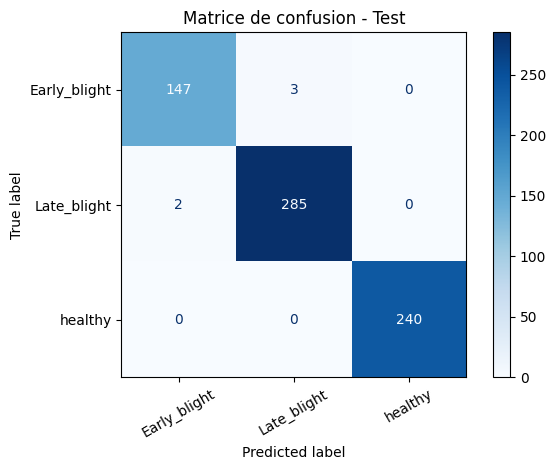

In [21]:
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)
import numpy as np
import matplotlib.pyplot as plt

model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for inputs, labels in test_loader_ft:
        inputs = inputs.to(device)
        outputs = model(inputs)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions)
        y_true.extend(labels.numpy())

test_acc = accuracy_score(y_true, y_pred)

print(f"Test Accuracy : {test_acc * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2],
    target_names=train_ds_ft.base.classes,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        c.replace("Tomato___", "")
        for c in train_ds_ft.base.classes
    ]
)
disp.plot(cmap="Blues", xticks_rotation=30)
plt.title("Matrice de confusion - Test")
plt.tight_layout()
plt.savefig(
    "/content/fine_tuning_results/confusion_matrix.png",
    dpi=150, bbox_inches="tight"
)
plt.show()

In [22]:
from google.colab import files
import os

for filename in [
    "best_resnet50_finetuning.pth",
    "training_history_ft.csv",
    "accuracy_curve.png",
    "loss_curve.png",
    "confusion_matrix.png"
]:
    filepath = os.path.join(RESULTS_FT, filename)
    if os.path.exists(filepath):
        files.download(filepath)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
print(f"Test Accuracy : {test_acc * 100:.2f}%")

Test Accuracy : 99.26%


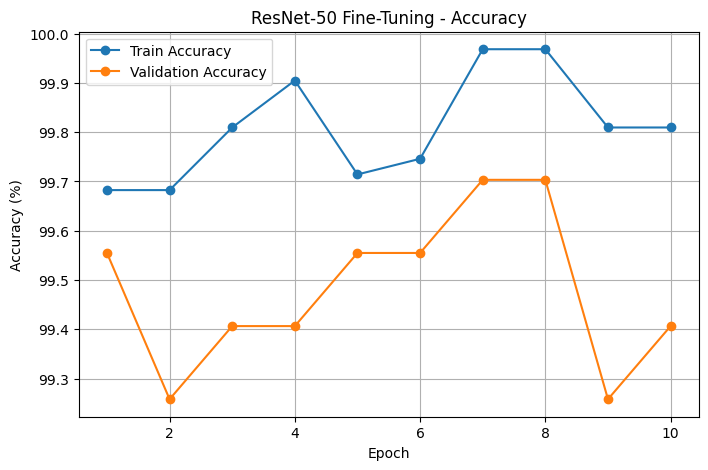

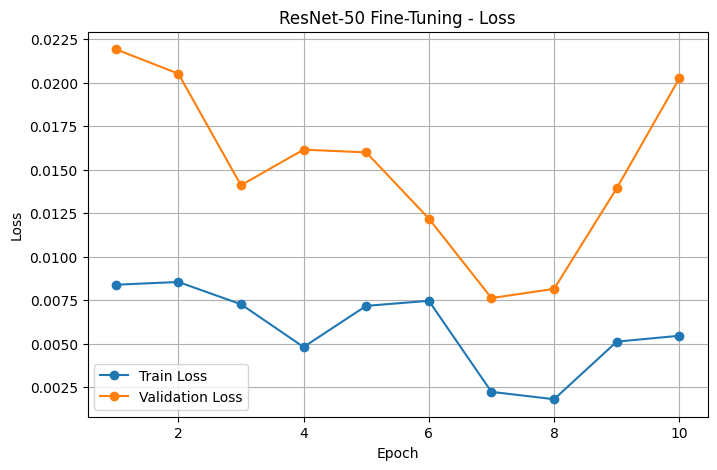

In [24]:
import matplotlib.pyplot as plt

epochs = [h["epoch"] for h in history_ft]

# Courbes Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, [h["train_accuracy"] * 100 for h in history_ft],
         marker="o", label="Train Accuracy")
plt.plot(epochs, [h["val_accuracy"] * 100 for h in history_ft],
         marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet-50 Fine-Tuning - Accuracy")
plt.legend()
plt.grid(True)
plt.savefig("/content/fine_tuning_results/accuracy_curve.png",
            dpi=150, bbox_inches="tight")
plt.show()

# Courbes Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, [h["train_loss"] for h in history_ft],
         marker="o", label="Train Loss")
plt.plot(epochs, [h["val_loss"] for h in history_ft],
         marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet-50 Fine-Tuning - Loss")
plt.legend()
plt.grid(True)
plt.savefig("/content/fine_tuning_results/loss_curve.png",
            dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
#hana

In [25]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torchvision import models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [26]:
model_fe = models.resnet50(weights=None)

model_fe.fc = nn.Linear(
    model_fe.fc.in_features,
    len(CLASSES)
)

model_fe.load_state_dict(
    torch.load(
        "/content/feature_extraction_results/best_resnet50_feature_extraction.pth",
        map_location=device
    )
)

model_fe = model_fe.to(device)
model_fe.eval()

y_true_fe = []
y_pred_fe = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        outputs = model_fe(inputs)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_true_fe.extend(labels.numpy())
        y_pred_fe.extend(predictions)

y_true_fe = np.array(y_true_fe)
y_pred_fe = np.array(y_pred_fe)

accuracy_fe = accuracy_score(y_true_fe, y_pred_fe)
precision_fe = precision_score(
    y_true_fe, y_pred_fe,
    average="weighted",
    zero_division=0
)
recall_fe = recall_score(
    y_true_fe, y_pred_fe,
    average="weighted",
    zero_division=0
)
f1_fe = f1_score(
    y_true_fe, y_pred_fe,
    average="weighted",
    zero_division=0
)

print(f"Accuracy  : {accuracy_fe * 100:.2f}%")
print(f"Precision : {precision_fe * 100:.2f}%")
print(f"Recall    : {recall_fe * 100:.2f}%")
print(f"F1-score  : {f1_fe * 100:.2f}%")

Accuracy  : 96.60%
Precision : 96.60%
Recall    : 96.60%
F1-score  : 96.60%


In [27]:
print(
    classification_report(
        y_true_fe,
        y_pred_fe,
        labels=[0, 1, 2],
        target_names=train_ds.classes,
        zero_division=0,
        digits=4
    )
)

                       precision    recall  f1-score   support

Tomato___Early_blight     0.9267    0.9267    0.9267       150
 Tomato___Late_blight     0.9617    0.9617    0.9617       287
     Tomato___healthy     0.9958    0.9958    0.9958       240

             accuracy                         0.9660       677
            macro avg     0.9614    0.9614    0.9614       677
         weighted avg     0.9660    0.9660    0.9660       677



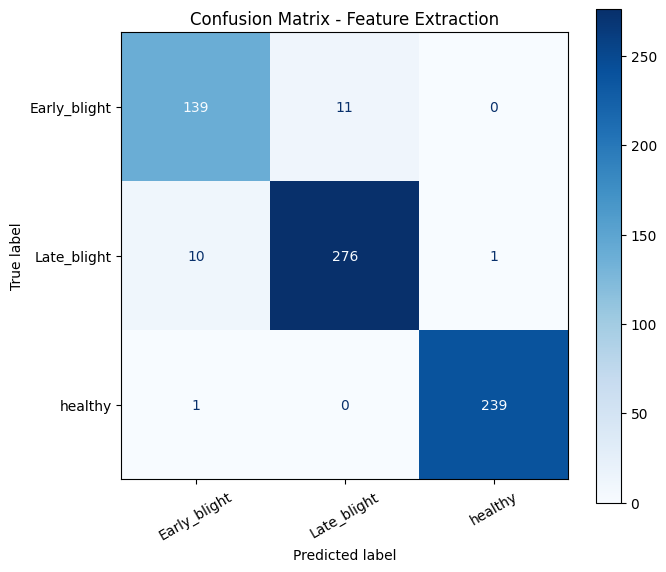

In [28]:
cm_fe = confusion_matrix(
    y_true_fe,
    y_pred_fe,
    labels=[0, 1, 2]
)

display_labels = [
    c.replace("Tomato___", "")
    for c in train_ds.classes
]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_fe,
    display_labels=display_labels
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=30
)

plt.title("Confusion Matrix - Feature Extraction")
plt.tight_layout()
plt.show()

In [29]:
model_ft = models.resnet50(weights=None)

model_ft.fc = nn.Linear(
    model_ft.fc.in_features,
    len(CLASSES)
)

model_ft.load_state_dict(
    torch.load(
        "/content/fine_tuning_results/best_resnet50_finetuning.pth",
        map_location=device
    )
)

model_ft = model_ft.to(device)
model_ft.eval()

y_true_ft = []
y_pred_ft = []

with torch.no_grad():
    for inputs, labels in test_loader_ft:
        inputs = inputs.to(device)

        outputs = model_ft(inputs)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_true_ft.extend(labels.numpy())
        y_pred_ft.extend(predictions)

y_true_ft = np.array(y_true_ft)
y_pred_ft = np.array(y_pred_ft)

accuracy_ft = accuracy_score(y_true_ft, y_pred_ft)

precision_ft = precision_score(
    y_true_ft, y_pred_ft,
    average="weighted",
    zero_division=0
)

recall_ft = recall_score(
    y_true_ft, y_pred_ft,
    average="weighted",
    zero_division=0
)

f1_ft = f1_score(
    y_true_ft, y_pred_ft,
    average="weighted",
    zero_division=0
)

print(f"Accuracy  : {accuracy_ft * 100:.2f}%")
print(f"Precision : {precision_ft * 100:.2f}%")
print(f"Recall    : {recall_ft * 100:.2f}%")
print(f"F1-score  : {f1_ft * 100:.2f}%")

Accuracy  : 99.26%
Precision : 99.26%
Recall    : 99.26%
F1-score  : 99.26%


In [30]:
print(
    classification_report(
        y_true_ft,
        y_pred_ft,
        labels=[0, 1, 2],
        target_names=train_ds_ft.base.classes,
        zero_division=0,
        digits=4
    )
)

                       precision    recall  f1-score   support

Tomato___Early_blight     0.9866    0.9800    0.9833       150
 Tomato___Late_blight     0.9896    0.9930    0.9913       287
     Tomato___healthy     1.0000    1.0000    1.0000       240

             accuracy                         0.9926       677
            macro avg     0.9921    0.9910    0.9915       677
         weighted avg     0.9926    0.9926    0.9926       677



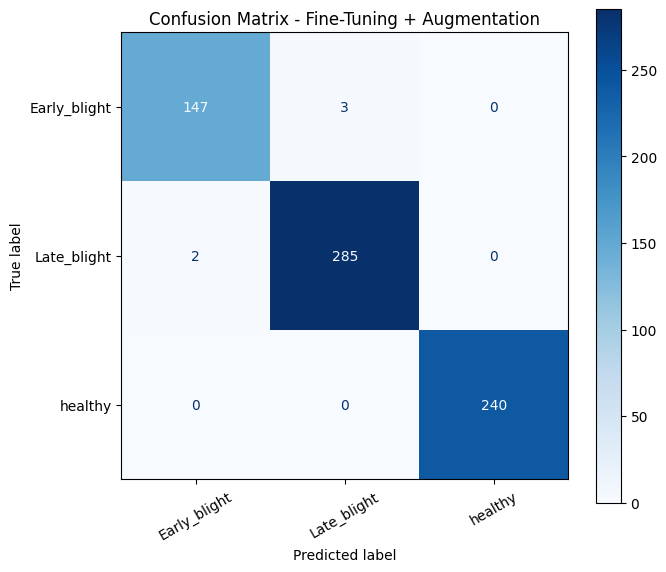

In [31]:
cm_ft = confusion_matrix(
    y_true_ft,
    y_pred_ft,
    labels=[0, 1, 2]
)

display_labels = [
    c.replace("Tomato___", "")
    for c in train_ds_ft.base.classes
]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ft,
    display_labels=display_labels
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=30
)

plt.title("Confusion Matrix - Fine-Tuning + Augmentation")
plt.tight_layout()
plt.show()

In [32]:
comparison = pd.DataFrame({
    "Method": [
        "Feature Extraction",
        "Fine-Tuning + Augmentation"
    ],
    "Accuracy (%)": [
        accuracy_fe * 100,
        accuracy_ft * 100
    ],
    "Precision (%)": [
        precision_fe * 100,
        precision_ft * 100
    ],
    "Recall (%)": [
        recall_fe * 100,
        recall_ft * 100
    ],
    "F1-score (%)": [
        f1_fe * 100,
        f1_ft * 100
    ]
})

comparison = comparison.round(2)

display(comparison)

,Method,Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,Feature Extraction,96.60,96.60,96.60,96.60
1,Fine-Tuning + Augmentation,99.26,99.26,99.26,99.26


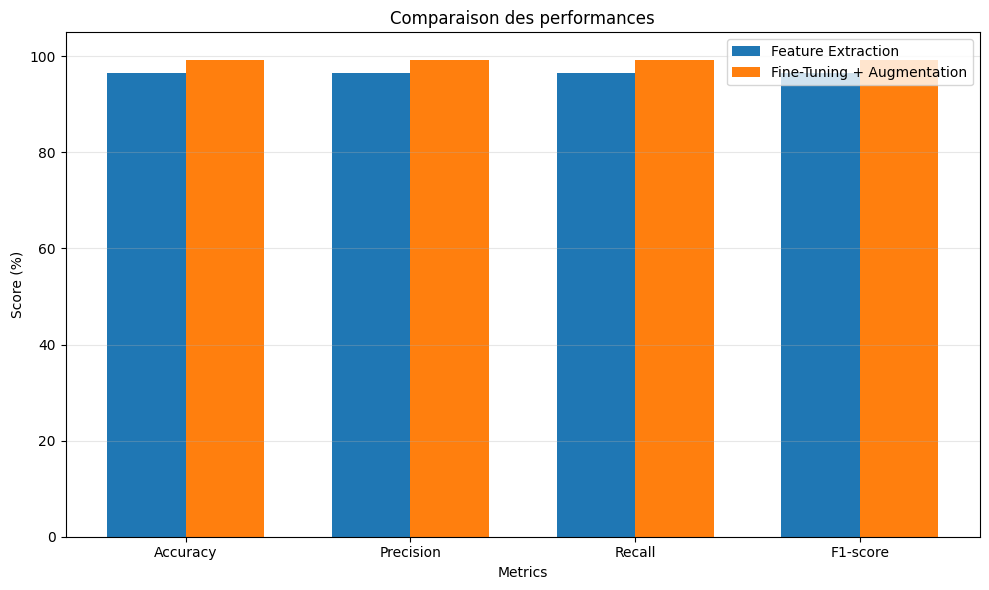

In [33]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

feature_values = [
    accuracy_fe * 100,
    precision_fe * 100,
    recall_fe * 100,
    f1_fe * 100
]

finetuning_values = [
    accuracy_ft * 100,
    precision_ft * 100,
    recall_ft * 100,
    f1_ft * 100
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    feature_values,
    width,
    label="Feature Extraction"
)

plt.bar(
    x + width / 2,
    finetuning_values,
    width,
    label="Fine-Tuning + Augmentation"
)

plt.xticks(x, metrics)
plt.ylabel("Score (%)")
plt.xlabel("Metrics")
plt.title("Comparaison des performances")
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

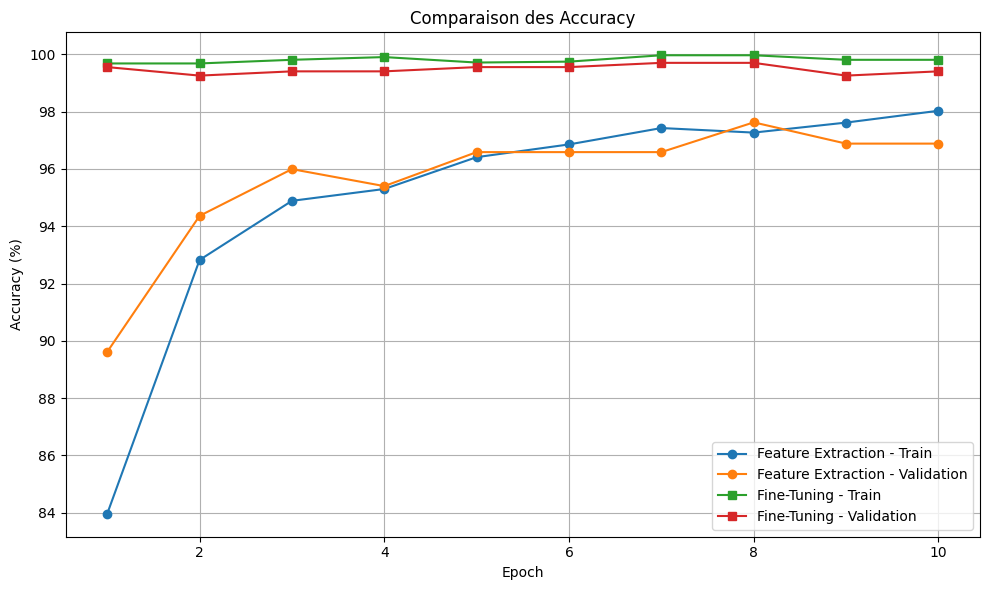

In [34]:
epochs_fe = [h["epoch"] for h in history]
epochs_ft = [h["epoch"] for h in history_ft]

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_fe,
    [h["train_accuracy"] * 100 for h in history],
    marker="o",
    label="Feature Extraction - Train"
)

plt.plot(
    epochs_fe,
    [h["val_accuracy"] * 100 for h in history],
    marker="o",
    label="Feature Extraction - Validation"
)

plt.plot(
    epochs_ft,
    [h["train_accuracy"] * 100 for h in history_ft],
    marker="s",
    label="Fine-Tuning - Train"
)

plt.plot(
    epochs_ft,
    [h["val_accuracy"] * 100 for h in history_ft],
    marker="s",
    label="Fine-Tuning - Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Comparaison des Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

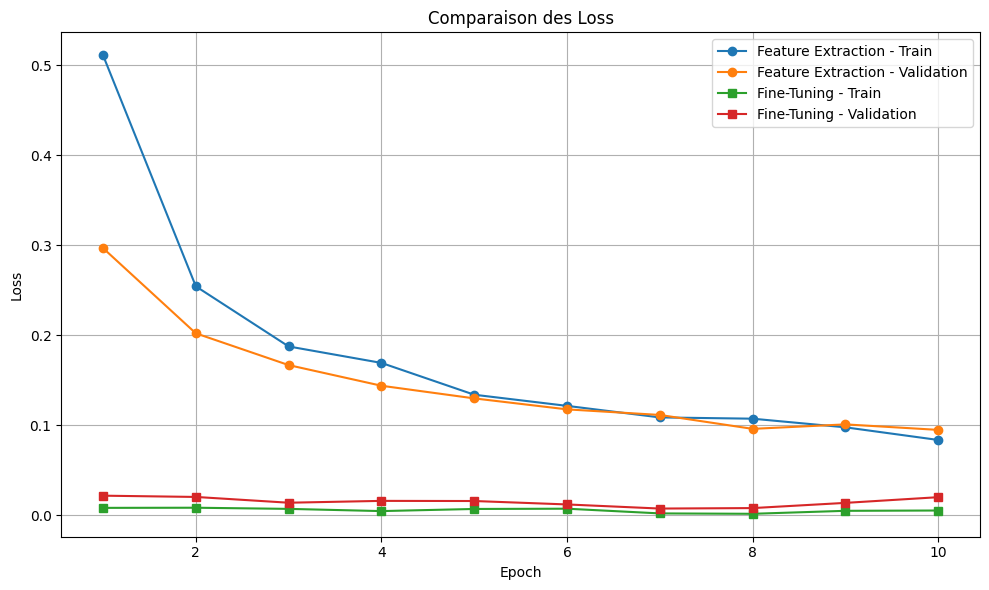

In [35]:
plt.figure(figsize=(10, 6))

plt.plot(
    epochs_fe,
    [h["train_loss"] for h in history],
    marker="o",
    label="Feature Extraction - Train"
)

plt.plot(
    epochs_fe,
    [h["val_loss"] for h in history],
    marker="o",
    label="Feature Extraction - Validation"
)

plt.plot(
    epochs_ft,
    [h["train_loss"] for h in history_ft],
    marker="s",
    label="Fine-Tuning - Train"
)

plt.plot(
    epochs_ft,
    [h["val_loss"] for h in history_ft],
    marker="s",
    label="Fine-Tuning - Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Comparaison des Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
os.makedirs("/content/student7_results", exist_ok=True)

comparison.to_csv(
    "/content/student7_results/comparison_results.csv",
    index=False
)

print("Tableau sauvegardé.")

In [ ]:
np.savetxt(
    "/content/student7_results/confusion_matrix_feature_extraction.csv",
    cm_fe,
    delimiter=",",
    fmt="%d"
)

np.savetxt(
    "/content/student7_results/confusion_matrix_finetuning.csv",
    cm_ft,
    delimiter=",",
    fmt="%d"
)

print("Matrices de confusion sauvegardées.")

In [36]:
print("Feature Extraction")
print(f"Accuracy  : {accuracy_fe * 100:.2f}%")
print(f"Precision : {precision_fe * 100:.2f}%")
print(f"Recall    : {recall_fe * 100:.2f}%")
print(f"F1-score  : {f1_fe * 100:.2f}%")

print("\nFine-Tuning + Augmentation")
print(f"Accuracy  : {accuracy_ft * 100:.2f}%")
print(f"Precision : {precision_ft * 100:.2f}%")
print(f"Recall    : {recall_ft * 100:.2f}%")
print(f"F1-score  : {f1_ft * 100:.2f}%")

Feature Extraction
Accuracy  : 96.60%
Precision : 96.60%
Recall    : 96.60%
F1-score  : 96.60%

Fine-Tuning + Augmentation
Accuracy  : 99.26%
Precision : 99.26%
Recall    : 99.26%
F1-score  : 99.26%
